# Modelo simple CNN

Este notebook implementa y entrena una **red neuronal convolucional (CNN)** para clasificar imágenes de fondo de ojo como "normal" o "glaucoma", utilizando los datos previamente procesados y almacenados en formato `.npy`.

Las principales actividades realizadas son:

- Carga de los conjuntos de datos `X_hand.npy` y `y_hand.npy`
- División en datos de entrenamiento y prueba
- Normalización de las imágenes y codificación one-hot de las etiquetas
- Definición e implementación de una arquitectura CNN básica con Keras, que incluye:
  - Capa convolucional `Conv2D`
  - Capa de reducción de dimensionalidad `MaxPooling2D`
  - Capa `Flatten` y capas `Dense` para clasificación
- Entrenamiento del modelo y evaluación del desempeño
- Visualización de la precisión y la pérdida del modelo por época
- Guardado del modelo entrenado en formato `.keras`

>  Este modelo sirve como punto de partida para tareas de clasificación de imágenes con redes neuronales profundas. Se sugiere mejorar su arquitectura como ejercicio adicional.


In [ ]:
# Herramienta de Google Colab para conectar el notebook con Google Drive
from google.colab import drive
# Monta (conecta) Google Drive en este entorno para poder leer y guardar archivos ahí
drive.mount('/content/MyDrive')

Mounted at /content/MyDrive


In [ ]:
import os
# Cambia la carpeta de trabajo actual a la carpeta del proyecto dentro de Drive
os.chdir('/content/MyDrive/MyDrive/Proyecto_glaucoma')

In [ ]:
!ls

Creacion_dataset_muestra.ipynb	modelo_CNN_3.keras
data_2000train_200val_240test	modelo_CNN_4.keras
data_raw			Parte_0_Generación_X_y.ipynb
Descarga_Datos_Kaggle.ipynb	Parte_1A_Modelo_CNN_AUG.ipynb
mejor_modelo_conservador.keras	Parte_1_Modelos_CNN.ipynb
modelo_CNN_2.keras		Parte2_prediccion_MatrizConfusion.ipynb


In [1]:
from numpy import load

X_train = load('data_2000train_200val_240test/train/X_train.npy')
y_train = load('data_2000train_200val_240test/train/y_train.npy')

X_val = load('data_2000train_200val_240test/val/X_val.npy')
y_val = load('data_2000train_200val_240test/val/y_val.npy')

FileNotFoundError: [Errno 2] No such file or directory: 'data_2000train_200val_240test/train/X_train.npy'

In [ ]:

print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)

(4000, 220, 220, 3)
(400, 220, 220, 3)
(4000,)
(400,)


In [ ]:
X_train_scaled  = X_train / 255
X_val_scaled  = X_val / 255

In [ ]:
# one hot encode outputs
#from tensorflow.keras.utils import to_categorical

#y_train = to_categorical( y_train )
#y_test = to_categorical( y_test )

In [ ]:
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout
from keras.layers import Flatten
#from keras.layers.convolutional import Conv2D
#from keras.layers.convolutional import MaxPooling2D
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D


# Primer modelo

Modelo

1. Conv 16 (3,3) , relu
2. MP (2,2)
7. Flatten
8. 128 , relu
9. num_classes, softmax

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.layers import Input # Added this import



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense, Dropout
from tensorflow.keras.layers import BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

def modelo_CNN():
    model = Sequential()

    model.add(Input(shape=(220, 220, 3)))

    # Capa convolucional: 'escanea' la imagen buscando patrones visuales como bordes, texturas y formas
    model.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
    # Normaliza las activaciones internas de la red, lo que suele acelerar y estabilizar el entrenamiento
    model.add(BatchNormalization())
    # Reduce el tamaño de la imagen quedándose con la información más relevante (submuestreo)
    model.add(MaxPooling2D((2, 2)))

    model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    model.add(GlobalAveragePooling2D())

    # Capa 'densa' o totalmente conectada: cada neurona recibe todas las salidas de la capa anterior
    model.add(Dense(128, activation='relu'))
    # Apaga aleatoriamente un porcentaje de neuronas durante el entrenamiento, para evitar que el modelo memorice en vez de aprender (sobreajuste)
    model.add(Dropout(0.4))

    model.add(Dense(1, activation='sigmoid'))

    # Configura el modelo antes de entrenar: qué función de pérdida usar, qué optimizador, y qué métricas medir
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
model = modelo_CNN()
# Entrena el modelo: le muestra los datos de entrenamiento repetidamente y ajusta sus pesos internos para reducir el error
history_CNN = model.fit(   X_train_scaled, y_train, validation_data = (X_val_scaled, y_val) ,
                        epochs = 100 , batch_size = 10, verbose=2  )

Epoch 1/100
400/400 - 13s - 33ms/step - accuracy: 0.6240 - loss: 0.6422 - val_accuracy: 0.5775 - val_loss: 0.6839
Epoch 2/100
400/400 - 2s - 6ms/step - accuracy: 0.6557 - loss: 0.6095 - val_accuracy: 0.6725 - val_loss: 0.6023
Epoch 3/100
400/400 - 2s - 6ms/step - accuracy: 0.6672 - loss: 0.5996 - val_accuracy: 0.6750 - val_loss: 0.6071
Epoch 4/100
400/400 - 2s - 6ms/step - accuracy: 0.6905 - loss: 0.5828 - val_accuracy: 0.6775 - val_loss: 0.5653
Epoch 5/100
400/400 - 2s - 6ms/step - accuracy: 0.6992 - loss: 0.5708 - val_accuracy: 0.6975 - val_loss: 0.5878
Epoch 6/100
400/400 - 2s - 6ms/step - accuracy: 0.7045 - loss: 0.5594 - val_accuracy: 0.7300 - val_loss: 0.5269
Epoch 7/100
400/400 - 2s - 6ms/step - accuracy: 0.7082 - loss: 0.5473 - val_accuracy: 0.7400 - val_loss: 0.5128
Epoch 8/100
400/400 - 2s - 6ms/step - accuracy: 0.7262 - loss: 0.5412 - val_accuracy: 0.7375 - val_loss: 0.5146
Epoch 9/100
400/400 - 2s - 6ms/step - accuracy: 0.7258 - loss: 0.5353 - val_accuracy: 0.7375 - val_los

In [ ]:
# Final evaluation of the model
# Evalúa el modelo ya entrenado sobre un conjunto de datos, devolviendo la pérdida y las métricas configuradas
scores=model.evaluate(X_val_scaled,y_val,verbose=0)

print('Error del modelo base : %.2f%%' % (100-scores[1]*100))

Error del modelo base : 17.50%


(0.0, 2.0)

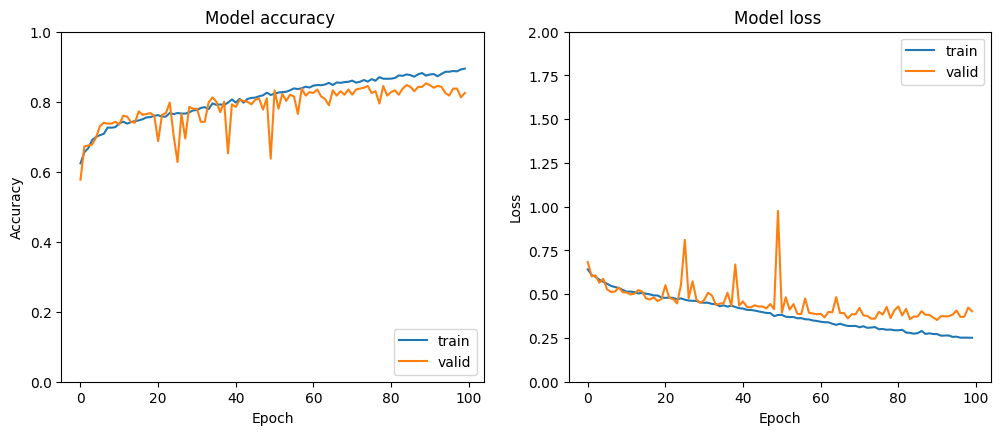

In [ ]:
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt

# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(12,10))
# Divide la figura en una cuadrícula y selecciona en qué posición dibujar
plt.subplot(2,2,1)
plt.plot(history_CNN.history['accuracy'])
plt.plot(history_CNN.history['val_accuracy'])
plt.ylim(0, 1)
# Agrega un título al gráfico o imagen mostrada
plt.title('Model accuracy ')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['train', 'valid'], loc='lower right')
plt.subplot(2,2,2)
plt.plot(history_CNN.history['loss'])
plt.plot(history_CNN.history['val_loss'])
plt.title('Model loss ')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'valid'], loc='upper right')
plt.ylim([0,2])

In [ ]:
# Guarda el modelo entrenado (su arquitectura y pesos aprendidos) en un archivo .keras para reutilizarlo sin re-entrenar
model.save('modelo_CNN_complejo.keras')

# Segundo Modelo (TAREA)
Encontrar un nuevo modelo que sea mejor